In [ ]:
import os
import random
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Paths
BASE_DIR = Path.cwd()

TRAIN_DIR = BASE_DIR / "model1_split" / "train"
VAL_DIR = BASE_DIR / "model1_split" / "val"

CHECKPOINT_DIR = BASE_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)

# Hyperparameters
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_EPOCHS = 30
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = min(4, os.cpu_count())
SEED = 42

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {device}")

Using device: cuda


In [3]:
# Data augmentation for training
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation preprocessing
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load datasets
train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    root=VAL_DIR,
    transform=val_transform
)

class_names = train_dataset.classes

print(f"Classes: {class_names}")
print(f"Training Images: {len(train_dataset)}")
print(f"Validation Images: {len(val_dataset)}")

Classes: ['MRI_DATA', 'NON_MRI_DATA']
Training Images: 10627
Validation Images: 2658


In [4]:
# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Class mapping: {train_dataset.class_to_idx}")

Training batches: 333
Validation batches: 84
Class mapping: {'MRI_DATA': 0, 'NON_MRI_DATA': 1}


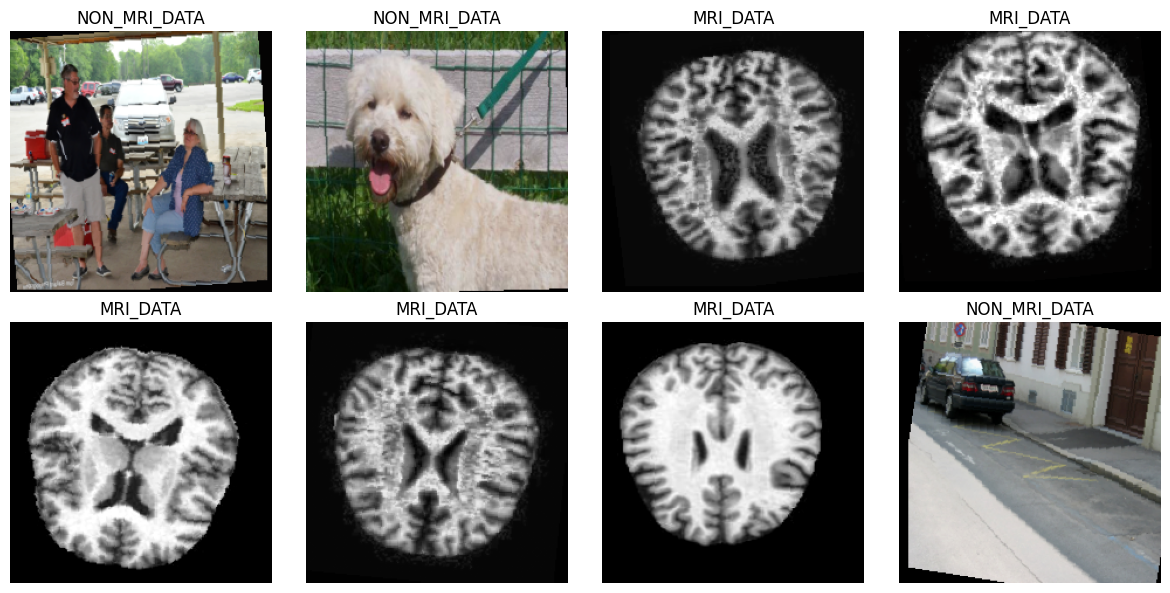

In [5]:
# Visualize augmented training images
images, labels = next(iter(train_loader))

# Undo ImageNet normalization for display
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    img = images[i] * std + mean
    img = img.clamp(0, 1)

    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(class_names[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
from collections import Counter
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Count training samples per class
targets = train_dataset.targets
class_counts = Counter(targets)

print("Class counts:")
for idx, count in class_counts.items():
    print(f"{class_names[idx]}: {count}")

# Compute balanced class weights
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(targets),
    y=targets
)

class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("\nClass weights:")
for idx, weight in enumerate(class_weights):
    print(f"{class_names[idx]}: {weight:.4f}")

Class counts:
MRI_DATA: 7727
NON_MRI_DATA: 2900

Class weights:
MRI_DATA: 0.6877
NON_MRI_DATA: 1.8322


In [7]:
# Load pretrained ResNet-18
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze feature extractor
for param in model.parameters():
    param.requires_grad = False

# Replace classifier
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(class_names))

# Train only the classifier
for param in model.fc.parameters():
    param.requires_grad = True

# Move model to device
model = model.to(device)

# Show trainable parameters
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

print(f"Trainable Parameters: {trainable_params:,}")
print(f"Total Parameters: {total_params:,}")

Trainable Parameters: 1,026
Total Parameters: 11,177,538


In [8]:
# Loss function
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Optimizer (train only unfrozen parameters)
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Loss Function :", criterion.__class__.__name__)
print("Optimizer     :", optimizer.__class__.__name__)
print("Scheduler     :", scheduler.__class__.__name__)

Loss Function : CrossEntropyLoss
Optimizer     : AdamW
Scheduler     : ReduceLROnPlateau


In [9]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


def validate_one_epoch(model, dataloader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

print("Training and validation functions are ready.")

Training and validation functions are ready.


In [10]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.early_stop = False

    def __call__(self, val_loss, model, save_path):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0

            torch.save(model.state_dict(), save_path)
            print(f"Validation loss improved. Model saved to {save_path.name}")

        else:
            self.counter += 1
            print(f"No improvement ({self.counter}/{self.patience})")

            if self.counter >= self.patience:
                self.early_stop = True

In [13]:
# Training history
import time
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

early_stopping = EarlyStopping(patience=5)

best_model_path = CHECKPOINT_DIR / "try1_best_model1.pth"

for epoch in range(NUM_EPOCHS):
    start_time = time.time()

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    elapsed_time = time.time() - start_time
    current_lr = optimizer.param_groups[0]["lr"]

    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")
    print(f"Learning Rate: {current_lr:.6f}")
    print(f"Time: {elapsed_time:.1f} sec")

    early_stopping(val_loss, model, best_model_path)

    if early_stopping.early_stop:
        print("\nEarly stopping triggered.")
        break


Epoch 1/30
Train Loss: 0.1238 | Train Acc: 97.85%
Val Loss:   0.0257 | Val Acc:   99.96%
Learning Rate: 0.000300
Time: 49.6 sec
Validation loss improved. Model saved to try1_best_model1.pth

Epoch 2/30
Train Loss: 0.0200 | Train Acc: 99.93%
Val Loss:   0.0104 | Val Acc:   99.96%
Learning Rate: 0.000300
Time: 47.5 sec
Validation loss improved. Model saved to try1_best_model1.pth

Epoch 3/30
Train Loss: 0.0112 | Train Acc: 99.94%
Val Loss:   0.0052 | Val Acc:   100.00%
Learning Rate: 0.000300
Time: 47.6 sec
Validation loss improved. Model saved to try1_best_model1.pth

Epoch 4/30
Train Loss: 0.0076 | Train Acc: 99.95%
Val Loss:   0.0036 | Val Acc:   100.00%
Learning Rate: 0.000300
Time: 50.7 sec
Validation loss improved. Model saved to try1_best_model1.pth

Epoch 5/30
Train Loss: 0.0055 | Train Acc: 99.96%
Val Loss:   0.0029 | Val Acc:   99.96%
Learning Rate: 0.000300
Time: 46.9 sec
Validation loss improved. Model saved to try1_best_model1.pth

Epoch 6/30
Train Loss: 0.0041 | Train Acc:

In [14]:
# Load the best model
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.to(device)
model.eval()

print(f"Best model loaded from:\n{best_model_path}")

Best model loaded from:
d:\Projects\ScanSarthi\ScanSaarthi\model1_things\checkpoints\try1_best_model1.pth


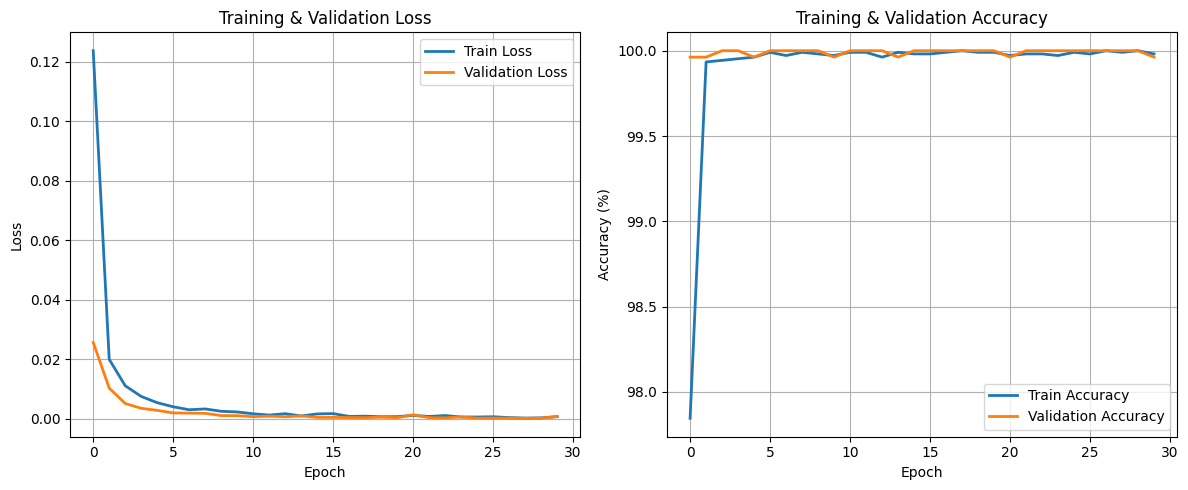

In [15]:
plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Train Loss", linewidth=2)
plt.plot(val_losses, label="Validation Loss", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.legend()
plt.grid(True)

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="Train Accuracy", linewidth=2)
plt.plot(val_accuracies, label="Validation Accuracy", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training & Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

(0.0, 0.03)

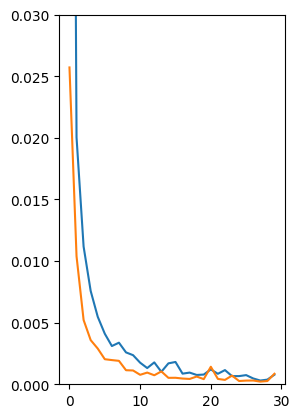

In [20]:
plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.ylim(0, 0.03)

In [21]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

all_labels = []
all_predictions = []
all_probabilities = []

In [22]:
model.eval()

all_labels.clear()
all_predictions.clear()
all_probabilities.clear()

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities[:, 1].cpu().numpy())

Classification Report

              precision    recall  f1-score   support

    MRI_DATA     1.0000    1.0000    1.0000      1932
NON_MRI_DATA     1.0000    1.0000    1.0000       726

    accuracy                         1.0000      2658
   macro avg     1.0000    1.0000    1.0000      2658
weighted avg     1.0000    1.0000    1.0000      2658



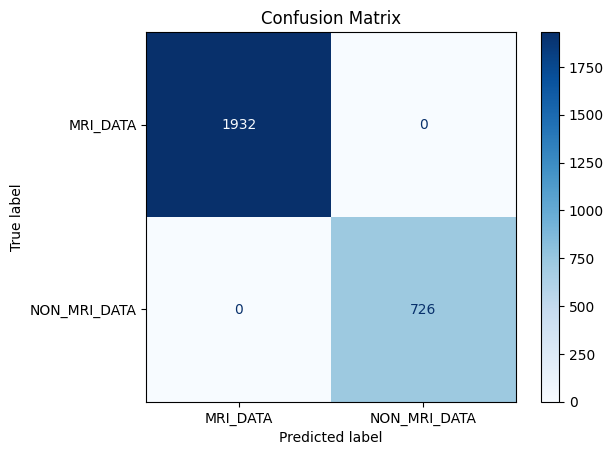

In [23]:
print("Classification Report\n")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4
))

cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

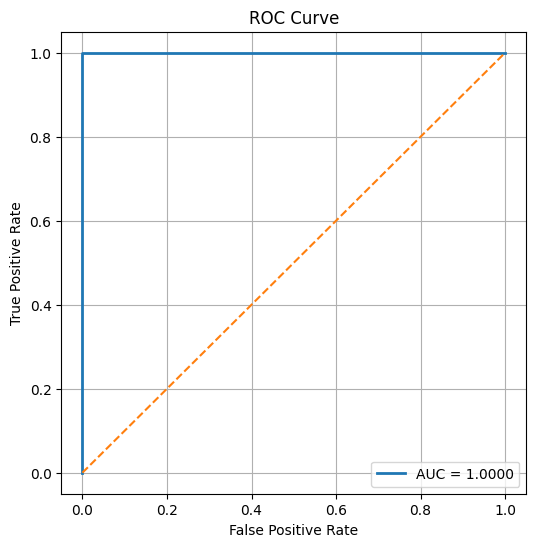

ROC-AUC Score: 1.0000


In [24]:
fpr, tpr, _ = roc_curve(all_labels, all_probabilities)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)

plt.show()

print(f"ROC-AUC Score: {roc_auc:.4f}")

In [25]:
print("Model Name      : ResNet18")
print("Task            : MRI vs Non-MRI")
print(f"Best Checkpoint : {best_model_path.name}")
print(f"Validation Acc  : {max(val_accuracies):.2f}%")
print(f"Best Val Loss   : {min(val_losses):.6f}")
print(f"ROC-AUC         : {roc_auc:.4f}")

Model Name      : ResNet18
Task            : MRI vs Non-MRI
Best Checkpoint : try1_best_model1.pth
Validation Acc  : 100.00%
Best Val Loss   : 0.000217
ROC-AUC         : 1.0000
